# Exercises XP - Heart Disease Prediction

This completed course notebook compares logistic regression, SVM, and XGBoost before and after hyperparameter tuning. The accompanying ZIP is the course dataset. Run the setup and then each cell in order. Use the results as a machine-learning exercise on this dataset.

The [UCI Statlog Heart data dictionary](https://archive.ics.uci.edu/dataset/145/statlog%2Bheart) documents the feature codes and outcome labels.

## Setup

In Colab, upload the accompanying ZIP if the download is unavailable. For local Jupyter, put it beside this notebook. Install pandas, matplotlib, scikit-learn (1.5 or newer), and xgboost if your environment needs them.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

## Exercise 1 - Exploratory Data Analysis

In [2]:
# Step 1. Load the course CSV from its ZIP. Prefer the local copy for offline use.
archive = Path("Heart Disease Prediction Dataset.zip")
url = ("https://media.githubusercontent.com/media/devtlv/Datasets-GEN-AI-Bootcamp/"
       "main/Week%205/Day%204%20-%20Statistics%20for%20Machine%20Learning/"
       "Heart%20Disease%20Prediction%20Dataset.zip")
if archive.exists():
    source = archive
else:
    with urlopen(url, timeout=30) as response:
        source = BytesIO(response.read())
with ZipFile(source) as zipped, zipped.open("dataset_heart.csv") as csv_file:
    df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()

# Step 2. Inspect dimensions, sample records, missing values and duplicates.
print(f"Shape: {df.shape} | Duplicates: {df.duplicated().sum()}")
print(df.head(3).T.to_string())
print(df.isna().sum().rename("Missing values").to_string())

# Step 3. Separate predictors from the outcome. For this dataset, 1 denotes
# absence and 2 denotes presence. Encode presence as the positive class (1).
target = "heart disease"
X = df.drop(columns=target)
y = df[target].map({1: 0, 2: 1})
assert y.notna().all() and y.nunique() == 2

# Step 4. Keep 20% of rows for testing. Stratification preserves class balance.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training rows: {len(y_train)} | Test rows: {len(y_test)}")

Shape: (270, 14) | Duplicates: 0
                                          0      1      2
age                                    70.0   67.0   57.0
sex                                     1.0    0.0    1.0
chest pain type                         4.0    3.0    2.0
resting blood pressure                130.0  115.0  124.0
serum cholestoral                     322.0  564.0  261.0
fasting blood sugar                     0.0    0.0    0.0
resting electrocardiographic results    2.0    2.0    0.0
max heart rate                        109.0  160.0  141.0
exercise induced angina                 0.0    0.0    0.0
oldpeak                                 2.4    1.6    0.3
ST segment                              2.0    2.0    1.0
major vessels                           3.0    0.0    0.0
thal                                    3.0    7.0    7.0
heart disease                           2.0    1.0    2.0
age                                     0
sex                                     0
chest pain ty

### Basic visual checks

         age  resting blood pressure  serum cholestoral  max heart rate
count  216.0                   216.0              216.0           216.0
mean    54.4                   131.1              248.3           150.6
std      9.3                    17.4               51.6            22.3
min     29.0                    94.0              126.0            95.0
25%     47.0                   120.0              211.8           133.0
50%     54.0                   130.0              243.0           153.5
75%     61.0                   140.0              282.0           168.0
max     77.0                   200.0              564.0           202.0


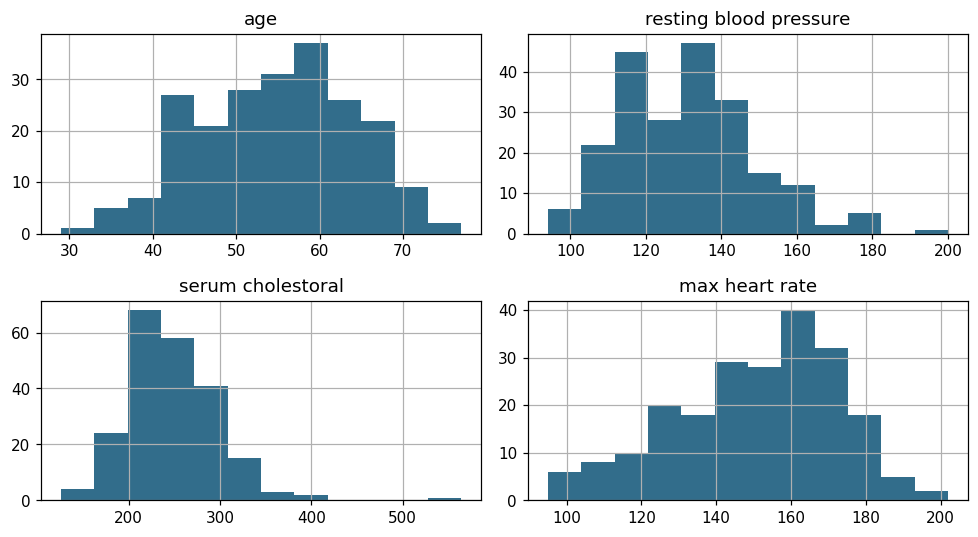

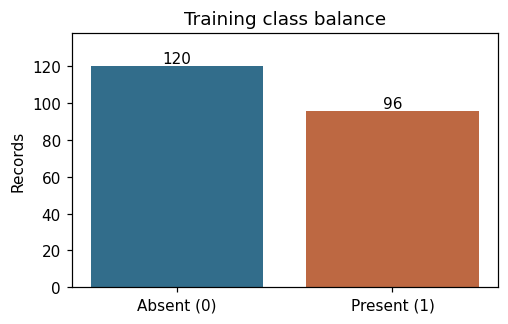

In [3]:
# Inspect predictor distributions and label balance on the training split.
columns = ["age", "resting blood pressure", "serum cholestoral", "max heart rate"]
X_train[columns].hist(bins=12, figsize=(9, 5), color="#326d8b")
plt.tight_layout()
plt.show()

counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["Absent (0)", "Present (1)"], counts.to_list(), color=["#326d8b", "#bd6842"])
ax.bar_label(bars)
ax.set(title="Training class balance", ylabel="Records", ylim=(0, max(counts) * 1.15))
plt.show()
print(X_train[columns].describe().round(1).to_string())

## Preprocessing pipeline

In [4]:
# Step 1. Several categorical variables are stored as integer codes. One-hot
# encoding avoids treating differences between arbitrary codes as distances.
categorical = [
    "sex", "chest pain type", "fasting blood sugar",
    "resting electrocardiographic results", "exercise induced angina",
    "ST segment", "thal",
]
numeric = [column for column in X_train.columns if column not in categorical]

# Step 2. Median-impute and scale measurements for logistic regression and
# SVM. Trees use the same encoding and imputation with no scaling needed.
def make_preprocessor(scale=True):
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler() if scale else "passthrough"),
        ]), numeric),
        ("categories", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
    ])

# Put this inside each model pipeline so CV learns preprocessing afresh
# using only the training portion of each fold.
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Helper - evaluation function

In [5]:
def eval_and_report(name, model, X_test, y_test):
    # Predict labels for threshold-based metrics and use a continuous score
    # for ROC AUC. SVM's decision_function provides an uncalibrated score.
    predictions = model.predict(X_test)
    scores = (model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba")
              else model.decision_function(X_test))
    results = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, scores),
    }
    print(pd.Series(results, name=name).round(3).to_string())
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], display_labels=["Absent", "Present"],
        cmap="Blues", colorbar=False, ax=axes[0]
    )
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()
    return results

def tune(pipeline, parameters):
    # Use training-fold F1 to balance positive-class precision and recall.
    # GridSearchCV refits the winning pipeline on all training rows.
    search = GridSearchCV(pipeline, parameters, cv=folds, scoring="f1", error_score="raise")
    search.fit(X_train, y_train)
    print(f"Best parameters: {search.best_params_}")
    print(f"Mean validation F1: {search.best_score_:.3f}")
    return search

## Exercise 2 - Logistic Regression without Grid Search

Accuracy     0.870
Precision    0.815
Recall       0.917
F1           0.863
ROC AUC      0.899


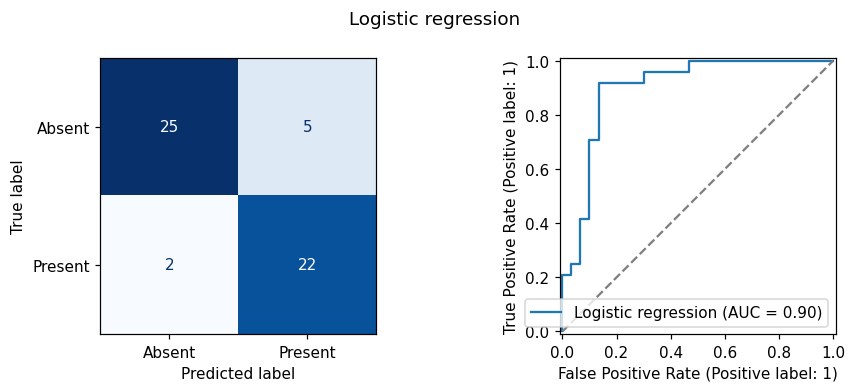

In [6]:
# Fit a fixed logistic regression baseline with L2 regularization and C=1.
pipe_lr = Pipeline([
    ("pre", make_preprocessor()),
    ("lr", LogisticRegression(solver="liblinear", penalty="l2", C=1, max_iter=2000)),
])
pipe_lr.fit(X_train, y_train)
lr_no_gs_metrics = eval_and_report("Logistic regression", pipe_lr, X_test, y_test)

## Exercise 3 - Logistic Regression with Grid Search

Best parameters: {'lr__C': 0.1, 'lr__penalty': 'l2'}
Mean validation F1: 0.811
Accuracy     0.870
Precision    0.840
Recall       0.875
F1           0.857
ROC AUC      0.912


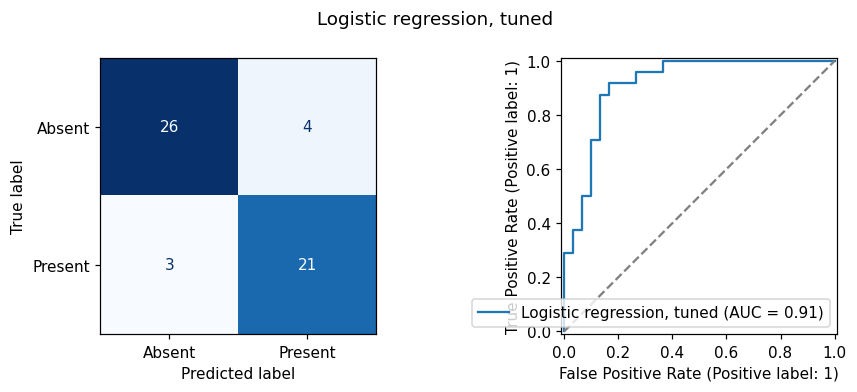

In [7]:
# Sweep inverse regularization strength C and compare L1 with L2.
grid_lr = tune(clone(pipe_lr), {
    "lr__C": [0.01, 0.1, 1, 10, 100],
    "lr__penalty": ["l1", "l2"],
})
lr_gs_metrics = eval_and_report("Logistic regression, tuned", grid_lr.best_estimator_, X_test, y_test)

## Exercise 4 - SVM without Grid Search

Accuracy     0.852
Precision    0.808
Recall       0.875
F1           0.840
ROC AUC      0.890


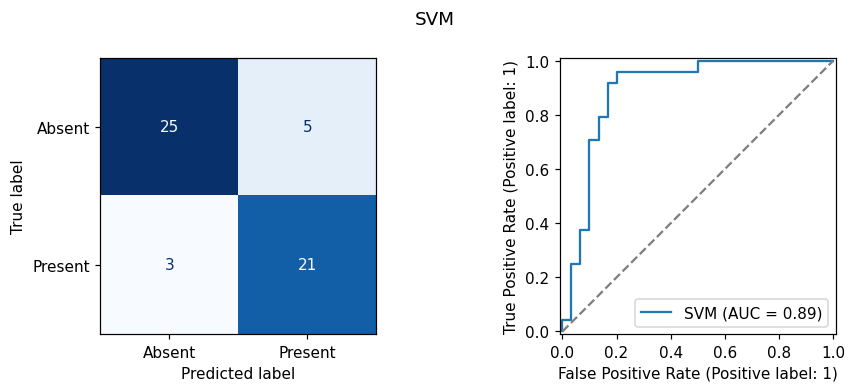

In [8]:
# Start with an RBF kernel to allow nonlinear boundaries. C=1 controls
# the error penalty and gamma='scale' adjusts kernel width to feature variance.
pipe_svm = Pipeline([
    ("pre", make_preprocessor()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
])
pipe_svm.fit(X_train, y_train)
svm_no_metrics = eval_and_report("SVM", pipe_svm, X_test, y_test)

## Exercise 5 - SVM with Grid Search

Best parameters: {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Mean validation F1: 0.835
Accuracy     0.852
Precision    0.833
Recall       0.833
F1           0.833
ROC AUC      0.911


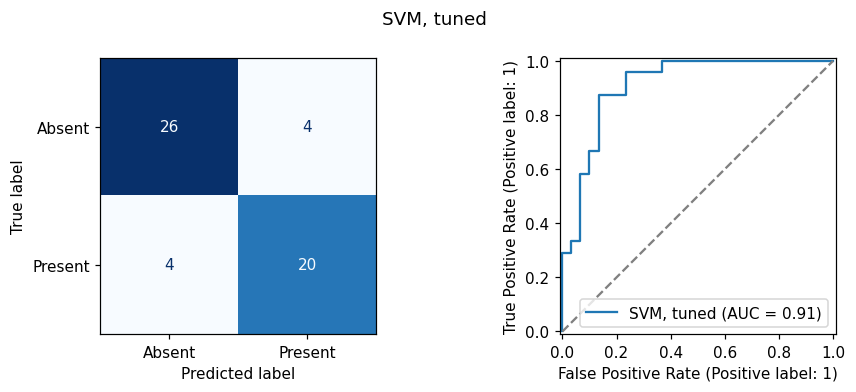

In [9]:
# Compare linear and RBF kernels. Gamma only changes the RBF model.
grid_svm = tune(clone(pipe_svm), [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10, 100]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": ["scale", "auto", 0.01, 0.1]},
])
svm_gs_metrics = eval_and_report("SVM, tuned", grid_svm.best_estimator_, X_test, y_test)

## Exercise 6 - XGBoost without Grid Search

Accuracy     0.833
Precision    0.800
Recall       0.833
F1           0.816
ROC AUC      0.851


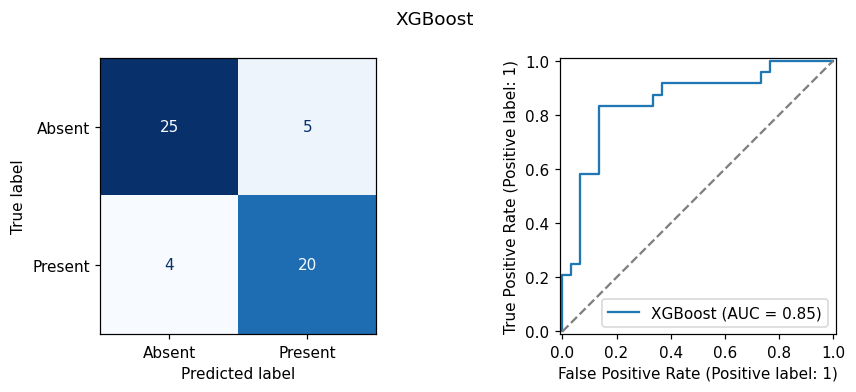

In [10]:
# Use shallow trees to limit complexity on this small dataset. A learning
# rate of 0.1 shrinks each update. 300 rounds give the model room to improve.
pipe_xgb = Pipeline([
    ("pre", make_preprocessor(scale=False)),
    ("xgb", XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                          n_estimators=300, learning_rate=0.1, max_depth=3,
                          random_state=42, n_jobs=1)),
])
pipe_xgb.fit(X_train, y_train)
xgb_no_metrics = eval_and_report("XGBoost", pipe_xgb, X_test, y_test)

## Exercise 7 - XGBoost with Grid Search

Best parameters: {'xgb__colsample_bytree': 1.0, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__n_estimators': 300, 'xgb__subsample': 1.0}
Mean validation F1: 0.806
Accuracy     0.796
Precision    0.760
Recall       0.792
F1           0.776
ROC AUC      0.864


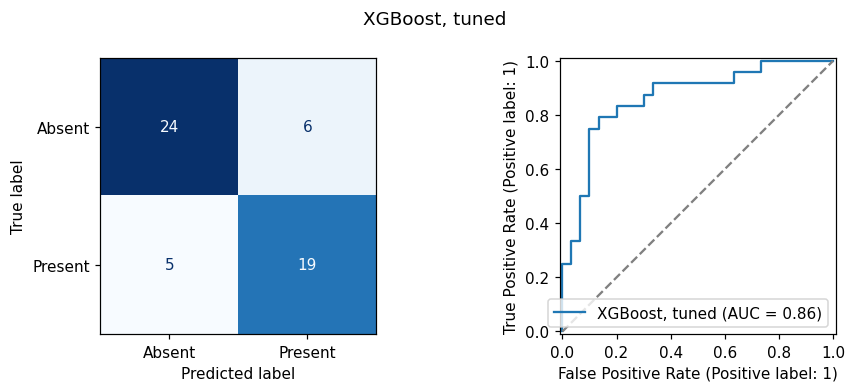

In [11]:
# Search boosting rounds, learning rate, tree depth, and row/column sampling.
grid_xgb = tune(clone(pipe_xgb), {
    "xgb__n_estimators": [100, 300],
    "xgb__learning_rate": [0.03, 0.1],
    "xgb__max_depth": [2, 3],
    "xgb__subsample": [0.8, 1.0],
    "xgb__colsample_bytree": [0.8, 1.0],
})
xgb_gs_metrics = eval_and_report("XGBoost, tuned", grid_xgb.best_estimator_, X_test, y_test)

## Compare models

In [12]:
# Compare each model on the same test rows. F1 balances precision and recall,
# while ROC AUC measures how well scores rank positives above negatives.
comparison = pd.DataFrame.from_dict({
    "Logistic regression": lr_no_gs_metrics,
    "Logistic regression, tuned": lr_gs_metrics,
    "SVM": svm_no_metrics,
    "SVM, tuned": svm_gs_metrics,
    "XGBoost": xgb_no_metrics,
    "XGBoost, tuned": xgb_gs_metrics,
}, orient="index")
print(comparison.round(3).to_string())
baseline = y_test.eq(y_train.mode().iat[0]).mean()
print(f"Majority-class test accuracy: {baseline:.3f}")

# Choose among tuned candidates with training CV scores, then report the
# chosen candidate's separately measured test results.
validation_f1 = pd.Series({
    "Logistic regression, tuned": grid_lr.best_score_,
    "SVM, tuned": grid_svm.best_score_,
    "XGBoost, tuned": grid_xgb.best_score_,
})
selected = validation_f1.idxmax()
print(f"Selected by training CV: {selected} (mean validation F1 {validation_f1.max():.3f})")
print(f"Held-out F1 for the selected model: {comparison.loc[selected, 'F1']:.3f}")

                            Accuracy  Precision  Recall     F1  ROC AUC
Logistic regression            0.870      0.815   0.917  0.863    0.899
Logistic regression, tuned     0.870      0.840   0.875  0.857    0.912
SVM                            0.852      0.808   0.875  0.840    0.890
SVM, tuned                     0.852      0.833   0.833  0.833    0.911
XGBoost                        0.833      0.800   0.833  0.816    0.851
XGBoost, tuned                 0.796      0.760   0.792  0.776    0.864
Majority-class test accuracy: 0.556
Selected by training CV: SVM, tuned (mean validation F1 0.835)
Held-out F1 for the selected model: 0.833


### Interpretation

Relative to their fixed baselines, tuning changed held-out F1 by -0.006 for logistic regression, -0.007 for SVM, and -0.041 for XGBoost. The test set contains 54 records, so small differences may change with another split. The source table has no missing entries or exact duplicates. Its training plots show both classes well represented and the cholesterol distribution extending farther on the high side.